In [1]:
import torch
import os
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU in Colab Runtime settings.")

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")

!nvidia-smi

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB
Fri Nov 13 15:44:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|        

In [6]:
%pip install -q -U \
    transformers \
    accelerate \
    datasets \
    peft \
    bitsandbytes \
    ftfy \
    tensorboard \
    safetensors \
    huggingface_hub

In [3]:
!git clone --depth 1 \
    https://github.com/huggingface/diffusers.git \
    /content/diffusers

Cloning into '/content/diffusers'...
remote: Enumerating objects: 3377, done.
remote: Counting objects: 100% (3377/3377), done.
remote: Compressing objects: 100% (2652/2652), done.
remote: Total 3377 (delta 1152), reused 1374 (delta 687), pack-reused 0 (from 0)
Receiving objects: 100% (3377/3377), 11.13 MiB | 12.64 MiB/s, done.
Resolving deltas: 100% (1152/1152), done.


In [4]:
%pip install -q -e /content/diffusers --no-deps

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusers (pyproject.toml) ... done


In [10]:
import diffusers
import transformers
import accelerate
import datasets
import peft
import bitsandbytes
import importlib.metadata

try:
    diffusers_version = diffusers.__version__
except AttributeError:
    try:
        diffusers_version = importlib.metadata.version("diffusers")
    except importlib.metadata.PackageNotFoundError:
        diffusers_version = "unknown (installed in editable mode)"

print("Diffusers:", diffusers_version)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("bitsandbytes:", bitsandbytes.__version__)

Diffusers: 0.44.0.dev0
Transformers: 5.23.0
Accelerate: 1.15.0
Datasets: 5.2.0
PEFT: 0.21.3
bitsandbytes: 0.50.2


In [11]:
from huggingface_hub import notebook_login

notebook_login()

README.md:   0%|          | 0.00/2.14k [00:00<?, ?B/s]

data/train-00000-of-00003-69df8b0a515682(…): reconstructing file:   0%|          |  0.00B /  518MB            

data/train-00000-of-00003-69df8b0a515682(…): downloading bytes:           |  0.00B            

data/train-00001-of-00003-8548ddd0333f4e(…): reconstructing file:   0%|          |  0.00B /  474MB            

data/train-00001-of-00003-8548ddd0333f4e(…): downloading bytes:           |  0.00B            

data/train-00002-of-00003-8b947414615b74(…): reconstructing file:   0%|          |  0.00B /  336MB            

data/train-00002-of-00003-8b947414615b74(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14904 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 14904
})
Total images: 14904
Columns: ['image', 'text']

Original caption:
outer, The North Face 1996 Eco Nuptse Jacket Black, a photography of the north face black down jacket


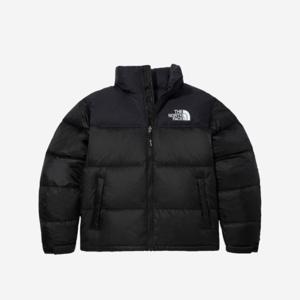

In [12]:
from datasets import load_dataset

DATASET_ID = "hahminlew/kream-product-blip-captions"

dataset = load_dataset(
    DATASET_ID,
    split="train"
)

print(dataset)
print("Total images:", len(dataset))
print("Columns:", dataset.column_names)

sample = dataset[0]

print("\nOriginal caption:")
print(sample["text"])

display(sample["image"].resize((300, 300)))

In [13]:
import random
from collections import defaultdict, Counter

TOTAL_IMAGES = 1500
TRAIN_COUNT = 1400
VAL_COUNT = 100

random.seed(42)

# Group dataset indices by product category.
category_indices = defaultdict(list)

for idx, text in enumerate(dataset["text"]):
    category = text.split(",", 1)[0].strip().lower()
    category_indices[category].append(idx)

print("Categories:")
for category, indices in category_indices.items():
    print(category, len(indices))

# Shuffle each category.
for category in category_indices:
    random.shuffle(category_indices[category])

# Round-robin sampling gives each category representation.
selected_indices = []

while len(selected_indices) < TOTAL_IMAGES:
    added = False

    for category in sorted(category_indices):
        if category_indices[category]:
            selected_indices.append(
                category_indices[category].pop()
            )
            added = True

            if len(selected_indices) == TOTAL_IMAGES:
                break

    if not added:
        break

random.shuffle(selected_indices)

selected_dataset = dataset.select(selected_indices)

print("Selected:", len(selected_dataset))

Categories:
outer 4963
top 4971
bottom 4970
Selected: 1500


In [14]:
def prepare_caption(original_caption):

    parts = original_caption.split(",", 2)

    if len(parts) == 3:
        category = parts[0].strip()
        visual_description = parts[2].strip()

        caption = (
            f"{category} fashion product, "
            f"{visual_description}"
        )
    else:
        caption = original_caption.strip()

    return caption


for i in range(5):
    print("Original:", selected_dataset[i]["text"])
    print("Training:", prepare_caption(selected_dataset[i]["text"]))
    print()

Original: outer,  Burberry Cotton Gabardine Trench Coat Sorbet Pink, a photography of a pink trench coat with a tan collar
Training: outer fashion product, a photography of a pink trench coat with a tan collar

Original: top, Saint James Minquiers Modern Striped Sailor Long Sleeve T-Shirt Noir Ecru, a photography of a black and white striped shirt with a long sleeve
Training: top fashion product, a photography of a black and white striped shirt with a long sleeve

Original: outer,  J.Lindeberg Stina Mid Layer Jacket Blue Horizon, a photography of a women's blue long sleeved shirt with a white logo
Training: outer fashion product, a photography of a women's blue long sleeved shirt with a white logo

Original: outer, Supreme Logo Piping Hooded Track Jacket Grey - 23FW, a photography of a white jacket with a pink hood and a black hood
Training: outer fashion product, a photography of a white jacket with a pink hood and a black hood

Original: top,  Maison Kitsune Fox Head Patch Adjusted R

In [15]:
import os
import json
import hashlib

from PIL import Image
from tqdm.auto import tqdm

BASE_DIR = "/content/fashion_data"

TRAIN_DIR = f"{BASE_DIR}/train"
VAL_DIR = f"{BASE_DIR}/validation"

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(VAL_DIR, exist_ok=True)

records = []

seen_hashes = set()

for i, row in enumerate(tqdm(selected_dataset)):

    try:
        image = row["image"].convert("RGB")

        # Detect exact/near-identical duplicates.
        fingerprint = hashlib.sha1(
            image.resize((64, 64)).tobytes()
        ).hexdigest()

        if fingerprint in seen_hashes:
            continue

        seen_hashes.add(fingerprint)

        caption = prepare_caption(row["text"])

        records.append({
            "image": image,
            "caption": caption
        })

    except Exception as e:
        print("Skipping image:", i, e)

random.shuffle(records)

train_records = records[:TRAIN_COUNT]
val_records = records[TRAIN_COUNT:TRAIN_COUNT + VAL_COUNT]

print("Train:", len(train_records))
print("Validation:", len(val_records))

  0%|          | 0/1500 [00:00<?, ?it/s]

Train: 1400
Validation: 93


In [16]:
def save_imagefolder(records, folder):

    metadata = []

    for i, record in enumerate(tqdm(records)):

        filename = f"{i:05d}.jpg"

        image_path = os.path.join(folder, filename)

        record["image"].save(
            image_path,
            format="JPEG",
            quality=95
        )

        metadata.append({
            "file_name": filename,
            "text": record["caption"]
        })

    metadata_path = os.path.join(
        folder, "metadata.jsonl"
    )

    with open(metadata_path, "w") as f:

        for item in metadata:
            f.write(json.dumps(item) + "\n")


save_imagefolder(train_records, TRAIN_DIR)
save_imagefolder(val_records, VAL_DIR)

print("Dataset preparation complete.")

  0%|          | 0/1400 [00:00<?, ?it/s]

  0%|          | 0/93 [00:00<?, ?it/s]

Dataset preparation complete.


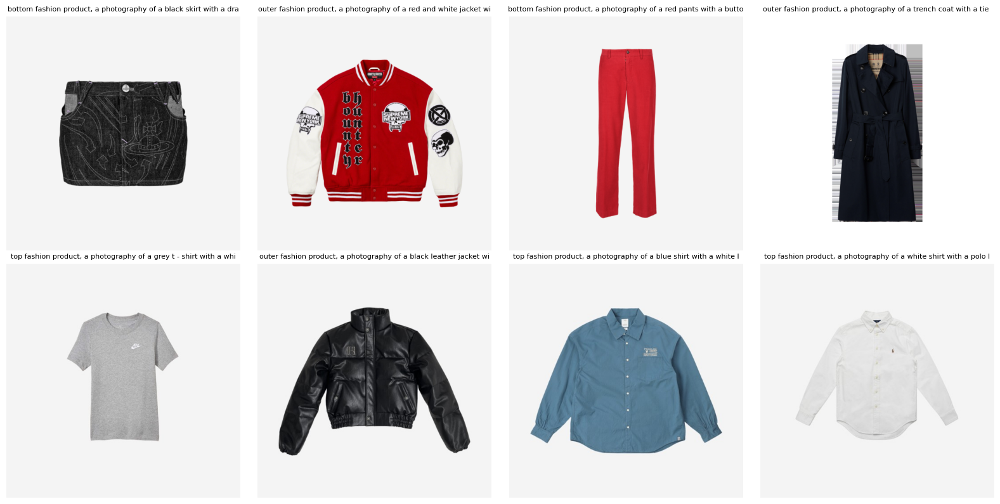

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, record in zip(axes.flatten(), train_records[:8]):

    ax.imshow(record["image"])
    ax.set_title(
        record["caption"][:65],
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
train_categories = Counter(
    r["caption"].split(" fashion product")[0]
    for r in train_records
)

print(train_categories)

Counter({'bottom': 469, 'top': 468, 'outer': 463})


Resolving data files:   0%|          | 0/1401 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 1400
})
['image', 'text']
bottom fashion product, a photography of a black skirt with a drawing on it


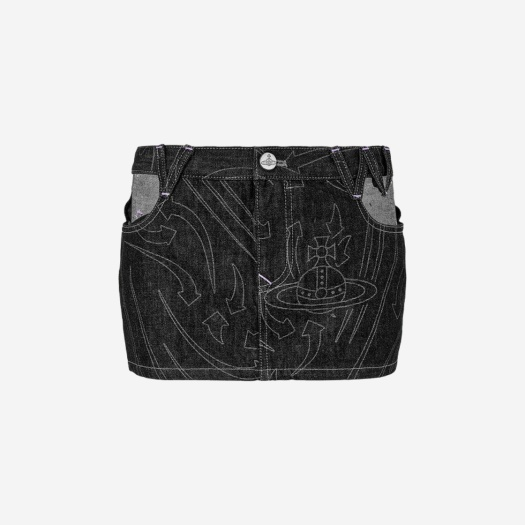

In [19]:
from datasets import load_dataset

train_dataset = load_dataset(
    "imagefolder",
    data_dir=TRAIN_DIR,
    split="train"
)

print(train_dataset)
print(train_dataset.column_names)

print(train_dataset[0]["text"])
display(train_dataset[0]["image"])

In [22]:
import sys
import importlib

# Point Python directly to the cloned repository source folder
if "/content/diffusers/src" not in sys.path:
    sys.path.insert(0, "/content/diffusers/src")

# Remove existing cached diffusers imports so that Python reloads it cleanly from the src directory
sys.modules.pop("diffusers", None)
importlib.invalidate_caches()

import torch
import os
import gc

from diffusers import StableDiffusionPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

EVAL_DIR = "/content/fashion_evaluation"
BASELINE_DIR = f"{EVAL_DIR}/baseline"
TUNED_DIR = f"{EVAL_DIR}/finetuned"

os.makedirs(BASELINE_DIR, exist_ok=True)
os.makedirs(TUNED_DIR, exist_ok=True)

# Use held-out validation captions.
eval_records = val_records[:12]

eval_prompts = [
    r["caption"] for r in eval_records
]

def generate_images(pipe, prompts, save_dir):

    generated = []

    for i, prompt in enumerate(prompts):

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(1000 + i)

        with torch.inference_mode():

            image = pipe(
                prompt,
                height=512,
                width=512,
                num_inference_steps=25,
                guidance_scale=7.0,
                generator=generator
            ).images[0]

        image.save(f"{save_dir}/{i:03d}.png")
        generated.append(image)

        print(f"Generated {i+1}/{len(prompts)}")

    return generated


# Load original model.
baseline_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True
).to("cuda")

baseline_pipe.set_progress_bar_config(disable=True)

# Generate baseline images.
baseline_images = generate_images(
    baseline_pipe,
    eval_prompts,
    BASELINE_DIR
)

del baseline_pipe
gc.collect()
torch.cuda.empty_cache()

print("Baseline evaluation complete.")

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/content/diffusers/src/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Generated 1/12
Generated 2/12
Generated 3/12
Generated 4/12
Generated 5/12
Generated 6/12
Generated 7/12
Generated 8/12
Generated 9/12
Generated 10/12
Generated 11/12
Generated 12/12
Baseline evaluation complete.


In [23]:
OUTPUT_DIR = "/content/fashion_lora_output"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Training directory:", TRAIN_DIR)
print("Output directory:", OUTPUT_DIR)

Training directory: /content/fashion_data/train
Output directory: /content/fashion_lora_output


In [24]:
%load_ext tensorboard
%tensorboard --logdir /content/fashion_lora_output/logs

<IPython.core.display.Javascript object>

In [27]:
%%bash

# Upgrade torchao to satisfy the dependency requirement in peft
pip install -q -U "torchao>=0.16.0"

MODEL_NAME="stable-diffusion-v1-5/stable-diffusion-v1-5"
TRAIN_DIR="/content/fashion_data/train"
OUTPUT_DIR="/content/fashion_lora_output"

accelerate launch \
    --num_processes=1 \
    --mixed_precision="no" \
    /content/diffusers/examples/text_to_image/train_text_to_image_lora.py \
    --pretrained_model_name_or_path=$MODEL_NAME \
    --train_data_dir=$TRAIN_DIR \
    --image_column="image" \
    --caption_column="text" \
    --resolution=512 \
    --center_crop \
    --train_batch_size=1 \
    --gradient_accumulation_steps=4 \
    --gradient_checkpointing \
    --use_8bit_adam \
    --rank=16 \
    --learning_rate=1e-4 \
    --lr_scheduler="cosine" \
    --lr_warmup_steps=100 \
    --max_train_steps=1500 \
    --checkpointing_steps=500 \
    --checkpoints_total_limit=2 \
    --dataloader_num_workers=2 \
    --max_grad_norm=1.0 \
    --seed=42 \
    --report_to="tensorboard" \
    --output_dir=$OUTPUT_DIR

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
W1113 16:00:57.124000 5302 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1113 16:00:57.180000 5302 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
11/13/2026 16:01:07 - INFO - __main__ - [RANK 0] Di

In [28]:
from diffusers import StableDiffusionPipeline
import torch
import gc
import os

OUTPUT_DIR = "/content/fashion_lora_output"

adapter_path = os.path.join(
    OUTPUT_DIR,
    "pytorch_lora_weights.safetensors"
)

assert os.path.exists(adapter_path), (
    "LoRA weights not found. Check training output."
)

finetuned_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True
).to("cuda")

finetuned_pipe.load_lora_weights(
    OUTPUT_DIR,
    weight_name="pytorch_lora_weights.safetensors"
)

finetuned_pipe.set_progress_bar_config(disable=True)

print("Fashion LoRA loaded successfully.")

/content/diffusers/src/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

W1113 18:12:33.530000 495 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Fashion LoRA loaded successfully.


In [29]:
finetuned_images = generate_images(
    finetuned_pipe,
    eval_prompts,
    TUNED_DIR
)

del finetuned_pipe

gc.collect()
torch.cuda.empty_cache()

print("Fine-tuned generation complete.")

Generated 1/12
Generated 2/12
Generated 3/12
Generated 4/12
Generated 5/12
Generated 6/12
Generated 7/12
Generated 8/12
Generated 9/12
Generated 10/12
Generated 11/12
Generated 12/12
Fine-tuned generation complete.


Prompt 1: outer fashion product, a photography of a black jacket with a hood and zippers
Prompt 2: outer fashion product, a photography of a black jacket with a zippered collar and a zip
Prompt 3: bottom fashion product, a photography of a tennis skirt with a logo on the side
Prompt 4: bottom fashion product, a photography of a pair of jeans on a white background
Prompt 5: top fashion product, a photography of a navy shirt with a red logo on the chest
Prompt 6: bottom fashion product, a photography of a green jogging pants with patches and a logo on the side
Prompt 7: top fashion product, a photography of a blue shirt with a white collar and a black stripe
Prompt 8: outer fashion product, a photography of a leopard print jacket with black leather sleeves


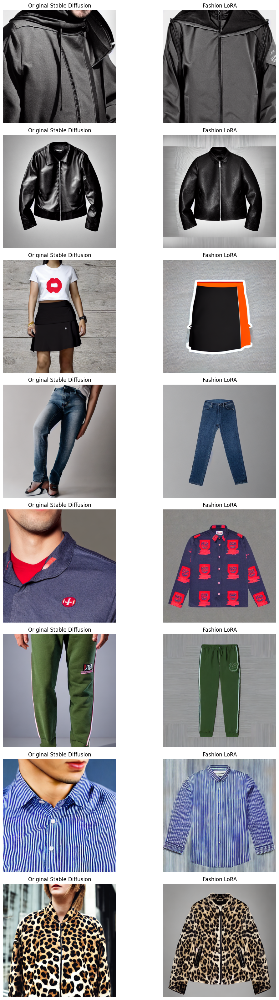

In [30]:
import matplotlib.pyplot as plt

N = min(8, len(eval_prompts))

fig, axes = plt.subplots(
    N, 2,
    figsize=(12, N * 4)
)

for i in range(N):

    axes[i, 0].imshow(baseline_images[i])
    axes[i, 0].set_title("Original Stable Diffusion")

    axes[i, 1].imshow(finetuned_images[i])
    axes[i, 1].set_title("Fashion LoRA")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

    print(f"Prompt {i+1}: {eval_prompts[i]}")

plt.tight_layout()
plt.show()

In [31]:
from transformers import CLIPModel, CLIPProcessor
import torch

CLIP_ID = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(
    CLIP_ID
).to("cuda")

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_ID
)

clip_model.eval()

print("Evaluation CLIP loaded.")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Evaluation CLIP loaded.


In [32]:
import numpy as np

def calculate_clip_scores(images, prompts):

    inputs = clip_processor(
        text=prompts,
        images=images,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {
        k: v.to("cuda")
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        outputs = clip_model(**inputs)

        image_embeddings = outputs.image_embeds
        text_embeddings = outputs.text_embeds

        image_embeddings = torch.nn.functional.normalize(
            image_embeddings,
            dim=-1
        )

        text_embeddings = torch.nn.functional.normalize(
            text_embeddings,
            dim=-1
        )

        similarities = (
            image_embeddings * text_embeddings
        ).sum(dim=-1)

    return similarities.cpu().numpy()


baseline_scores = calculate_clip_scores(
    baseline_images,
    eval_prompts
)

finetuned_scores = calculate_clip_scores(
    finetuned_images,
    eval_prompts
)

reference_images = [
    r["image"] for r in eval_records
]

reference_scores = calculate_clip_scores(
    reference_images,
    eval_prompts
)

print("Original SD CLIP score:",
      baseline_scores.mean())

print("Fashion LoRA CLIP score:",
      finetuned_scores.mean())

print("Real validation image CLIP score:",
      reference_scores.mean())

Original SD CLIP score: 0.32678905
Fashion LoRA CLIP score: 0.32244757
Real validation image CLIP score: 0.31084952


In [33]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Original SD 1.5",
        "Fashion LoRA",
        "Real validation images"
    ],
    "Mean CLIP similarity": [
        baseline_scores.mean(),
        finetuned_scores.mean(),
        reference_scores.mean()
    ]
})

display(results)

,Model,Mean CLIP similarity
0,Original SD 1.5,0.326789
1,Fashion LoRA,0.322448
2,Real validation images,0.310850


In [34]:
from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "Fashion_Stable_Diffusion_LoRA"
)

os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy2(
    "/content/fashion_lora_output/"
    "pytorch_lora_weights.safetensors",
    SAVE_DIR
)

print("Saved to:", SAVE_DIR)

Mounted at /content/drive
Saved to: /content/drive/MyDrive/Fashion_Stable_Diffusion_LoRA


/content/diffusers/src/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

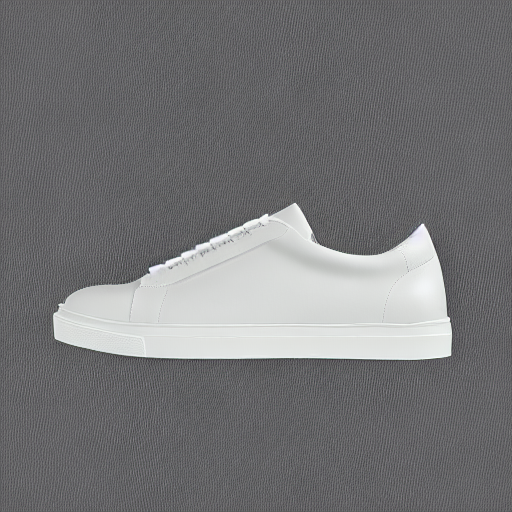

In [35]:
from diffusers import StableDiffusionPipeline
import torch

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

LORA_PATH = (
    "/content/drive/MyDrive/"
    "Fashion_Stable_Diffusion_LoRA"
)

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True
).to("cuda")

pipe.load_lora_weights(LORA_PATH)

prompt = """
shoes fashion product,
a pair of premium white leather sneakers,
minimalist design, clean studio product photography,
isolated on a light grey background,
high detail, realistic material texture
"""

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.0,
    generator=torch.Generator("cuda").manual_seed(123)
).images[0]

display(image)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

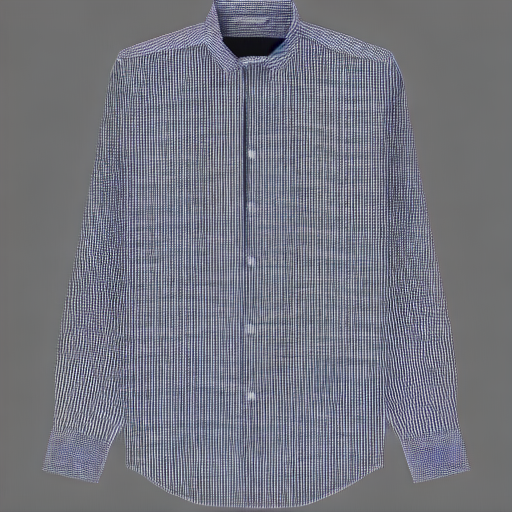

In [40]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

LORA_PATH = (
    "/content/drive/MyDrive/"
    "Fashion_Stable_Diffusion_LoRA"
)

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True
).to("cuda")

pipe.load_lora_weights(LORA_PATH)

prompt = """
shirt with

"""

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.0,
    generator=torch.Generator("cuda").manual_seed(123)
).images[0]

display(image)